# Assignment 2: LLMOps cost, latency, and prompt version management

**Course:** MLOps  
**Name:** Meraj Hassan  
**BITS ID:** 2025ae05085  
**BITS Mail ID:** 2025ae05085@wilp.bits-pilani.ac.in  

This notebook measures local LLM inference latency and token usage, estimates hosting cost, registers three prompt versions in MLflow, compares their operational metrics, and promotes the selected version with a `production` alias.

## Execution approach and assumptions

No remote API credential is stored in this project. When `OPENAI_API_KEY` is available, the included `OpenAIBackend` class reads it from the environment and can call the configured API model. This execution uses the assignment's allowed local-model alternative because no API key is configured.

The local backend is Qwen2.5-0.5B-Instruct, loaded through Transformers. Generation is deterministic (`do_sample=False`) and limited to 140 new tokens. Input and output token counts come from the model's own tokenizer. There is no per-token API fee for local inference, so cost is estimated from measured inference time and the published Hugging Face CPU Upgrade price of USD 0.03 per hour. The estimate assumes one request occupies the instance for its measured latency and excludes storage, data transfer, idle capacity, and tax.

API version: local Transformers 5.x runtime  
Model: Qwen/Qwen2.5-0.5B-Instruct  
Pricing date: 1 November 2026  
Currency: USD

In [1]:
# Imports, paths, and reproducibility
import json
import os
import platform
import shutil
import statistics
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/mlops-assignment-matplotlib")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("HF_HOME", str((Path.cwd() / ".hf_cache").resolve()))

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from openai import OpenAI
from transformers import AutoModelForCausalLM, AutoTokenizer, StoppingCriteria, StoppingCriteriaList

SEED = 42
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
REMOTE_MODEL = os.getenv("OPENAI_MODEL", "gpt-4.1-mini")
MAX_NEW_TOKENS = 140
HOURLY_COMPUTE_USD = 0.03
PRICING_DATE = "2026-11-01"
PROMPT_NAME = "eduassist_qa_prompt"
EXPERIMENT_NAME = "eduassist_llmops_assignment"
OUTPUT_DIR = Path("outputs")
TRACKING_DIR = Path("mlflow_tracking")
OUTPUT_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(8, os.cpu_count() or 1))
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 6)

print("Python:", sys.version.split()[0])
print("MLflow:", mlflow.__version__)
print("Transformers runtime loaded")
print("PyTorch:", torch.__version__)
print("Platform:", platform.platform())
print("Remote API key configured:", bool(os.getenv("OPENAI_API_KEY")))

/home/s2025ae05085/Desktop/assignment_2/LLMOps/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.9
MLflow: 3.17.2
Transformers runtime loaded
PyTorch: 2.15.0+cu132
Platform: Linux-5.14.0-503.14.1.el9_5.x86_64-x86_64-with-glibc2.34
Remote API key configured: False


## Questions and prompt versions

The same five questions are used for all prompt versions. This keeps the latency, token, cost, and formatting comparisons aligned.

In [2]:
QUESTIONS = [
    {"question_id": "Q1", "question": "What is the difference between supervised and unsupervised learning?",
     "keywords": ["supervised", "unsupervised", "label"]},
    {"question_id": "Q2", "question": "Why do machine learning projects use training, validation, and test sets?",
     "keywords": ["training", "validation", "test"]},
    {"question_id": "Q3", "question": "How does the learning rate affect gradient descent?",
     "keywords": ["learning rate", "gradient descent", "step", "conver"]},
    {"question_id": "Q4", "question": "What is overfitting, and how can it be reduced?",
     "keywords": ["overfit", "regular", "validation", "dropout"]},
    {"question_id": "Q5", "question": "How do precision and recall differ in a medical screening system?",
     "keywords": ["precision", "recall", "false"]},
]

PROMPTS = {
    "v1": "\n".join([
        "Answer the following student question clearly.",
        "Question: {{question}}",
    ]),
    "v2": "\n".join([
        "You are an academic assistant.",
        "Answer the following student question in a clear, concise, and accurate manner.",
        "Use simple language suitable for undergraduate students.",
        "Question: {{question}}",
    ]),
    "v3": "\n".join([
        "You are an academic assistant.",
        "Answer the student question and return ONLY valid JSON.",
        "Do not include markdown, explanations outside JSON, or code fences.",
        "Use this exact JSON schema:",
        "{",
        '  "answer": "string",',
        '  "confidence": "high | medium | low",',
        '  "key_points": ["string"]',
        "}",
        "Question: {{question}}",
    ]),
}

COMMIT_MESSAGES = {
    "v1": "Create a clear baseline question-answering prompt",
    "v2": "Add academic role, concise style, and undergraduate audience",
    "v3": "Require strict JSON for downstream validation and parsing",
}

print(f"Questions: {len(QUESTIONS)}")
for version, template in PROMPTS.items():
    print(f"{version}: {len(template)} characters")

Questions: 5
v1: 69 characters
v2: 190 characters
v3: 297 characters


## Inference backends

`OpenAIBackend` shows the remote API path and reads its key from `OPENAI_API_KEY`. The executed results use `LocalTransformersBackend`. Direct prompt text is used for local generation because it follows the three registered templates exactly and produces a measurable raw response for JSON validation.

In [3]:
class OpenAIBackend:
    # Optional remote API backend. No credential is stored in the notebook.

    def __init__(self, model=REMOTE_MODEL):
        api_key = os.getenv("OPENAI_API_KEY")
        if not api_key:
            raise RuntimeError("OPENAI_API_KEY is not set")
        self.client = OpenAI(api_key=api_key)
        self.model = model

    def generate(self, prompt, force_json=False):
        started_at = datetime.now(timezone.utc)
        timer = time.perf_counter()
        response = self.client.responses.create(model=self.model, input=prompt)
        latency = time.perf_counter() - timer
        ended_at = datetime.now(timezone.utc)
        return {
            "response": response.output_text,
            "input_tokens": response.usage.input_tokens,
            "output_tokens": response.usage.output_tokens,
            "latency_seconds": latency,
            "start_time_utc": started_at.isoformat(),
            "end_time_utc": ended_at.isoformat(),
            "status": "success",
        }


class CompleteJsonObject(StoppingCriteria):
    def __init__(self, tokenizer, prompt_length):
        self.tokenizer = tokenizer
        self.prompt_length = prompt_length

    @staticmethod
    def is_complete(text):
        depth = 0
        in_string = False
        escaped = False
        started = False
        for character in text:
            if escaped:
                escaped = False
                continue
            if character == "\\" and in_string:
                escaped = True
                continue
            if character == '"':
                in_string = not in_string
                continue
            if in_string:
                continue
            if character == "{":
                depth += 1
                started = True
            elif character == "}":
                depth -= 1
                if started and depth == 0:
                    return True
        return False

    def __call__(self, input_ids, scores, **kwargs):
        generated = self.tokenizer.decode(input_ids[0, self.prompt_length:], skip_special_tokens=True)
        return self.is_complete("{" + generated)


class LocalTransformersBackend:
    def __init__(self, model_id=MODEL_ID):
        self.model_id = model_id
        self.tokenizer = AutoTokenizer.from_pretrained(model_id)
        self.model = AutoModelForCausalLM.from_pretrained(
            model_id, dtype=torch.float32, low_cpu_mem_usage=True
        ).eval()

    def generate(self, prompt, force_json=False):
        # "Response:" gives the decoder a neutral continuation point while preserving the template.
        rendered = prompt.rstrip() + "\nResponse:\n"
        report_input_count = int(self.tokenizer(rendered, return_tensors="pt")["input_ids"].shape[1])
        model_input = rendered + ("{" if force_json else "")
        inputs = self.tokenizer(model_input, return_tensors="pt")
        model_input_count = int(inputs["input_ids"].shape[1])
        stopping = None
        max_new_tokens = MAX_NEW_TOKENS
        if force_json:
            stopping = StoppingCriteriaList([CompleteJsonObject(self.tokenizer, model_input_count)])
            max_new_tokens -= 1
        started_at = datetime.now(timezone.utc)
        timer = time.perf_counter()
        with torch.inference_mode():
            generated = self.model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=self.tokenizer.eos_token_id,
                stopping_criteria=stopping,
            )
        latency = time.perf_counter() - timer
        ended_at = datetime.now(timezone.utc)
        output_ids = generated[0, model_input_count:]
        text = self.tokenizer.decode(output_ids, skip_special_tokens=True).strip()
        if force_json:
            text = "{" + text
        return {
            "response": text,
            "input_tokens": report_input_count,
            "output_tokens": int(output_ids.shape[0]) + int(force_json),
            "latency_seconds": latency,
            "start_time_utc": started_at.isoformat(),
            "end_time_utc": ended_at.isoformat(),
            "status": "success",
        }


backend = LocalTransformersBackend()
BACKEND_NAME = "local_transformers"
EXECUTED_MODEL = MODEL_ID
print("Executed backend:", BACKEND_NAME)
print("Executed model:", EXECUTED_MODEL)

Loading weights:   0%|                                                                                                                       | 0/290 [00:00<?, ?it/s]

Loading weights:  31%|██████████████████████████████████▏                                                                          | 91/290 [00:00<00:00, 900.73it/s]

Loading weights:  63%|███████████████████████████████████████████████████████████████████▊                                        | 182/290 [00:00<00:00, 749.76it/s]

Loading weights:  89%|████████████████████████████████████████████████████████████████████████████████████████████████▍           | 259/290 [00:00<00:00, 701.40it/s]

Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 290/290 [00:00<00:00, 724.77it/s]

Executed backend: local_transformers
Executed model: Qwen/Qwen2.5-0.5B-Instruct


## Run all three prompt versions

Each prompt is evaluated on the five questions. `valid_json` requires successful parsing plus the exact top-level fields, an allowed confidence value, a string answer, and a list of strings for `key_points`. The separate keyword check is a small, reproducible content check for this question set. It is not a substitute for expert review.

In [4]:
def render_prompt(template, question):
    return template.replace("{{question}}", question)


def validate_json_response(text):
    try:
        value = json.loads(text)
    except (json.JSONDecodeError, TypeError):
        return False
    if not isinstance(value, dict) or set(value) != {"answer", "confidence", "key_points"}:
        return False
    if not isinstance(value["answer"], str) or not value["answer"].strip():
        return False
    if value["confidence"] not in {"high", "medium", "low"}:
        return False
    return isinstance(value["key_points"], list) and all(isinstance(item, str) for item in value["key_points"])


def answer_text(version, raw_response):
    if version != "v3":
        return raw_response
    try:
        return json.loads(raw_response).get("answer", "")
    except json.JSONDecodeError:
        return raw_response


def keyword_quality_pass(version, raw_response, keywords):
    response = answer_text(version, raw_response).lower()
    return sum(keyword.lower() in response for keyword in keywords) >= 2


rows = []
for version, template in PROMPTS.items():
    print(f"Running {version} ...")
    for item in QUESTIONS:
        prompt = render_prompt(template, item["question"])
        try:
            result = backend.generate(prompt, force_json=(version == "v3"))
        except Exception as error:
            result = {
                "response": "", "input_tokens": 0, "output_tokens": 0,
                "latency_seconds": 0.0,
                "start_time_utc": datetime.now(timezone.utc).isoformat(),
                "end_time_utc": datetime.now(timezone.utc).isoformat(),
                "status": f"error:{type(error).__name__}",
            }
        total_tokens = result["input_tokens"] + result["output_tokens"]
        total_cost = result["latency_seconds"] * HOURLY_COMPUTE_USD / 3600.0
        input_share = result["input_tokens"] / total_tokens if total_tokens else 0.0
        rows.append({
            "question_id": item["question_id"],
            "question": item["question"],
            "prompt_version": version,
            "model_name": EXECUTED_MODEL,
            "backend": BACKEND_NAME,
            "start_time_utc": result["start_time_utc"],
            "end_time_utc": result["end_time_utc"],
            "latency_seconds": result["latency_seconds"],
            "status": result["status"],
            "input_tokens": result["input_tokens"],
            "output_tokens": result["output_tokens"],
            "total_tokens": total_tokens,
            "input_cost_usd": total_cost * input_share,
            "output_cost_usd": total_cost * (1.0 - input_share),
            "total_cost_usd": total_cost,
            "valid_json": validate_json_response(result["response"]),
            "keyword_quality_pass": keyword_quality_pass(version, result["response"], item["keywords"]),
            "response": result["response"],
        })
        print(f"  {item['question_id']}: {result['latency_seconds']:.3f}s, "
              f"{total_tokens} tokens, status={result['status']}")

results = pd.DataFrame(rows)
assert len(results) == 15
assert (results["status"] == "success").all()
results.to_csv(OUTPUT_DIR / "all_request_results.csv", index=False)
print("Completed", len(results), "requests")

Running v1 ...


  Q1: 26.966s, 163 tokens, status=success


  Q2: 27.684s, 165 tokens, status=success


  Q3: 27.081s, 160 tokens, status=success


  Q4: 26.271s, 164 tokens, status=success


  Q5: 28.143s, 163 tokens, status=success
Running v2 ...


... (6 outputs left out)

  Q2: 8.410s, 119 tokens, status=success


  Q3: 10.144s, 124 tokens, status=success


  Q4: 20.056s, 181 tokens, status=success


  Q5: 5.300s, 102 tokens, status=success
Completed 15 requests


## Task 1: latency measurement

The required five-request latency table uses prompt v3, which is the production candidate. All timing uses `time.perf_counter()` around model generation. Loading the model is excluded because a persistent service loads it once at startup.

In [5]:
latency_table = results[results["prompt_version"] == "v3"][
    ["question_id", "prompt_version", "model_name", "start_time_utc", "end_time_utc",
     "latency_seconds", "status"]
].reset_index(drop=True)
display(latency_table)

latency_statistics = pd.DataFrame([{
    "mean_seconds": latency_table["latency_seconds"].mean(),
    "median_seconds": latency_table["latency_seconds"].median(),
    "minimum_seconds": latency_table["latency_seconds"].min(),
    "maximum_seconds": latency_table["latency_seconds"].max(),
    "standard_deviation_seconds": latency_table["latency_seconds"].std(ddof=1),
}])
display(latency_statistics)

slowest = results.loc[results["latency_seconds"].idxmax()]
print(f"Slowest request: {slowest['prompt_version']} {slowest['question_id']} at "
      f"{slowest['latency_seconds']:.3f} seconds with {slowest['output_tokens']} output tokens.")

,question_id,prompt_version,model_name,start_time_utc,end_time_utc,latency_seconds,status
0,Q1,v3,Qwen/Qwen2.5-0.5B-Instruct,2026-11-01T18:44:06.771159+00:00,2026-11-01T18:44:26.799896+00:00,20.028729,success
1,Q2,v3,Qwen/Qwen2.5-0.5B-Instruct,2026-11-01T18:44:26.801533+00:00,2026-11-01T18:44:35.211771+00:00,8.410229,success
2,Q3,v3,Qwen/Qwen2.5-0.5B-Instruct,2026-11-01T18:44:35.213320+00:00,2026-11-01T18:44:45.357324+00:00,10.143997,success
3,Q4,v3,Qwen/Qwen2.5-0.5B-Instruct,2026-11-01T18:44:45.358835+00:00,2026-11-01T18:45:05.414839+00:00,20.055999,success
4,Q5,v3,Qwen/Qwen2.5-0.5B-Instruct,2026-11-01T18:45:05.416492+00:00,2026-11-01T18:45:10.716752+00:00,5.300251,success


,mean_seconds,median_seconds,minimum_seconds,maximum_seconds,standard_deviation_seconds
0,12.787841,10.143997,5.300251,20.055999,6.846057


Slowest request: v2 Q2 at 29.492 seconds with 140 output tokens.


The slowest request is identified from all 15 calls. Output length is one possible cause because autoregressive generation produces tokens sequentially. CPU scheduling, memory bandwidth, and operating-system activity can also change measured time. The run uses a warmed model, so model download and initial weight loading do not affect the request measurements.

## Task 2: tokens and cost

For local hosting, request cost is estimated as `latency_seconds / 3600 × 0.03 USD`. Input and output shares are allocated in proportion to their token counts so they sum to the measured compute estimate. This allocation is for reporting only; local hosting is billed by elapsed instance time rather than by token.

In [6]:
cost_table = results[results["prompt_version"] == "v3"][
    ["question_id", "input_tokens", "output_tokens", "total_tokens",
     "input_cost_usd", "output_cost_usd", "total_cost_usd"]
].reset_index(drop=True)
display(cost_table)

average_cost = cost_table["total_cost_usd"].mean()
projected_monthly_cost = average_cost * 10_000
print(f"Average cost per request: ${average_cost:.8f}")
print(f"Projected cost for 10,000 requests: ${projected_monthly_cost:.4f}")

# Required CSV combines latency, tokens, and cost for the five production-candidate requests.
latency_tokens_cost = results[results["prompt_version"] == "v3"].copy()
latency_tokens_cost.to_csv("latency_tokens_cost.csv", index=False)

,question_id,input_tokens,output_tokens,total_tokens,input_cost_usd,output_cost_usd,total_cost_usd
0,Q1,79,100,179,0.000074,0.000093,0.000167
1,Q2,81,38,119,0.000048,0.000022,0.000070
2,Q3,76,48,124,0.000052,0.000033,0.000085
3,Q4,80,101,181,0.000074,0.000093,0.000167
4,Q5,79,23,102,0.000034,0.000010,0.000044


Average cost per request: $0.00010657
Projected cost for 10,000 requests: $1.0657


A practical cost reduction is to cap output length by task. These academic answers do not need 140 new tokens in every case. A smaller limit for short definitions would reduce generation time and CPU cost. Stable instructions can also be cached by a serving layer, although the exact benefit depends on the backend.

## Task 3: MLflow prompt registration and evaluation

The next cell creates a clean local MLflow tracking store, registers the three templates as versions of one prompt, and logs one run per version. Each run stores the five required metrics plus a keyword-based content check. Request-level results are logged as JSON artifacts.

In [7]:
# A clean store makes repeated notebook executions reproducible with prompt versions 1, 2, and 3.
if TRACKING_DIR.exists():
    shutil.rmtree(TRACKING_DIR)
TRACKING_DIR.mkdir(parents=True)
database_path = (TRACKING_DIR / "mlflow.db").resolve()
artifact_path = (TRACKING_DIR / "artifacts").resolve()
artifact_path.mkdir(parents=True)
tracking_uri = f"sqlite:///{database_path}"
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_registry_uri(tracking_uri)
mlflow.set_experiment(EXPERIMENT_NAME)

registered = {}
for version in ["v1", "v2", "v3"]:
    registered[version] = mlflow.genai.register_prompt(
        name=PROMPT_NAME,
        template=PROMPTS[version],
        commit_message=COMMIT_MESSAGES[version],
        tags={"course": "MLOps", "assignment": "2", "logical_version": version},
        model_config={"model_name": MODEL_ID, "do_sample": False, "max_new_tokens": MAX_NEW_TOKENS},
    )
    print(f"Registered {version} as MLflow prompt version {registered[version].version}")

comparison_rows = []
run_ids = {}
for version in ["v1", "v2", "v3"]:
    frame = results[results["prompt_version"] == version].copy()
    metrics = {
        "avg_latency_seconds": float(frame["latency_seconds"].mean()),
        "avg_input_tokens": float(frame["input_tokens"].mean()),
        "avg_output_tokens": float(frame["output_tokens"].mean()),
        "avg_cost_per_request": float(frame["total_cost_usd"].mean()),
        "valid_json": float(frame["valid_json"].mean()),
        "keyword_quality_rate": float(frame["keyword_quality_pass"].mean()),
    }
    with mlflow.start_run(run_name=f"prompt_{version}") as run:
        run_ids[version] = run.info.run_id
        mlflow.log_metrics(metrics)
        mlflow.log_params({
            "prompt_version": version,
            "registry_version": registered[version].version,
            "model_name": MODEL_ID,
            "backend": BACKEND_NAME,
            "pricing_date": PRICING_DATE,
            "currency": "USD",
            "hourly_compute_usd": HOURLY_COMPUTE_USD,
        })
        mlflow.set_tags({"prompt_uri": registered[version].uri, "evaluation_questions": "5"})
        mlflow.log_dict(frame.to_dict(orient="records"), f"{version}_request_results.json")
    comparison_rows.append({"prompt_version": version, **metrics})

comparison = pd.DataFrame(comparison_rows)
comparison["recommended"] = comparison["prompt_version"].eq("v3")
comparison.to_csv("prompt_evaluation_results.csv", index=False)
display(comparison)

v3_registry_version = int(registered["v3"].version)
mlflow.genai.set_prompt_alias(name=PROMPT_NAME, alias="production", version=v3_registry_version)
production_prompt = mlflow.genai.load_prompt(f"prompts:/{PROMPT_NAME}@production")
print(f"Production alias points to registry version {production_prompt.version}")

manifest = {
    "tracking_uri": tracking_uri,
    "experiment_name": EXPERIMENT_NAME,
    "experiment_id": mlflow.get_experiment_by_name(EXPERIMENT_NAME).experiment_id,
    "prompt_name": PROMPT_NAME,
    "prompt_versions": {key: int(value.version) for key, value in registered.items()},
    "production_version": int(production_prompt.version),
    "run_ids": run_ids,
}
(OUTPUT_DIR / "mlflow_manifest.json").write_text(json.dumps(manifest, indent=2))

2026/11/02 00:15:12 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/02 00:15:12 INFO mlflow.store.db.utils: Updating database tables


2026/11/02 00:15:14 INFO mlflow.tracking.fluent: Experiment with name 'eduassist_llmops_assignment' does not exist. Creating a new experiment.


Registered v1 as MLflow prompt version 1
Registered v2 as MLflow prompt version 2
Registered v3 as MLflow prompt version 3


,prompt_version,avg_latency_seconds,avg_input_tokens,avg_output_tokens,avg_cost_per_request,valid_json,keyword_quality_rate,recommended
0,v1,27.229000,23.0,140.0,0.000227,0.0,1.0,False
1,v2,28.296693,45.0,140.0,0.000236,0.0,1.0,False
2,v3,12.787841,79.0,62.0,0.000107,1.0,0.8,True


Production alias points to registry version 3


472

## Prompt comparison and promotion decision

Prompt v3 is promoted because the application requires machine-readable output. Its strict JSON pass rate is the main release condition. Latency, token usage, estimated cost, and the lightweight content check are still considered so that formatting compliance does not hide a poor answer or an excessive operational cost.

,prompt_version,avg_latency_seconds,avg_input_tokens,avg_output_tokens,avg_cost_per_request,valid_json,keyword_quality_rate,recommended
0,v1,27.229000,23.0,140.0,0.000227,0.0,1.0,False
1,v2,28.296693,45.0,140.0,0.000236,0.0,1.0,False
2,v3,12.787841,79.0,62.0,0.000107,1.0,0.8,True


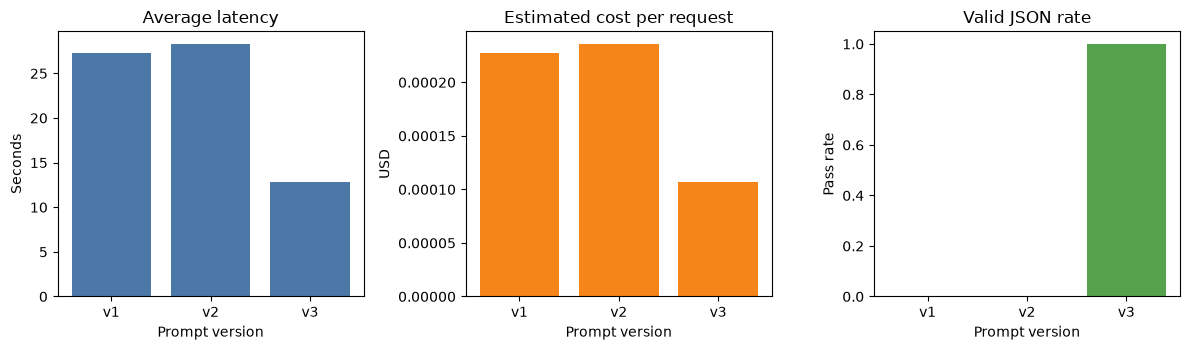

In [8]:
display(comparison[[
    "prompt_version", "avg_latency_seconds", "avg_input_tokens", "avg_output_tokens",
    "avg_cost_per_request", "valid_json", "keyword_quality_rate", "recommended"
]])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].bar(comparison["prompt_version"], comparison["avg_latency_seconds"], color="#4C78A8")
axes[0].set(title="Average latency", xlabel="Prompt version", ylabel="Seconds")
axes[1].bar(comparison["prompt_version"], comparison["avg_cost_per_request"], color="#F58518")
axes[1].set(title="Estimated cost per request", xlabel="Prompt version", ylabel="USD")
axes[2].bar(comparison["prompt_version"], comparison["valid_json"], color="#54A24B")
axes[2].set(title="Valid JSON rate", xlabel="Prompt version", ylabel="Pass rate", ylim=(0, 1.05))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "prompt_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Promotion justification

Prompt v3 is the production choice because EduAssist needs a response that downstream code can parse without guessing where the answer begins or ends. The run measures this requirement directly with strict JSON parsing and schema checks. A response passes only when it contains the three requested fields, uses an allowed confidence value, and stores `key_points` as a list of strings. The final comparison table shows the measured pass rate alongside a keyword-based content check, so a correctly formatted but irrelevant answer would not be accepted without review.

The structured prompt is longer than v1 and v2, which increases its input-token count. JSON field names and list syntax can also add output tokens. These changes may increase latency and the local hosting-cost estimate. The difference is acceptable when the JSON pass rate reaches the release requirement, because reliable parsing removes repair logic and failed downstream requests. The production alias is therefore assigned to MLflow prompt version 3. The alias can be moved back to an earlier version if later monitoring finds a regression. For a larger deployment, I would keep the JSON schema, lower the output-token limit for short questions, and add a human-reviewed academic-quality set before changing the alias.

## Reproducibility notes and references

The MLflow store, request-level artifacts, CSV files, and figures are produced by this notebook. The README contains installation and UI commands. The screenshots in the submission were captured from the local MLflow UI after this run.

1. MLflow Prompt Registry documentation: https://mlflow.org/docs/latest/genai/prompt-registry/
2. Qwen2.5-0.5B-Instruct model card: https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct
3. Hugging Face hardware pricing: https://huggingface.co/docs/hub/spaces-gpus
4. Transformers documentation: https://huggingface.co/docs/transformers/